In [4]:
import pandas as pd
import numpy as np

In [20]:
data = pd.read_csv("Instagram visits clustering.csv",sep=",")
data

,User ID,Instagram visit score,Spending_rank(0 to 100)
0,0,63,24.050708
1,1,61,25.223290
2,2,104,18.528245
3,3,82,86.890232
4,4,14,31.492397
...,...,...,...
2595,2595,25,25.745908
2596,2596,52,9.275066
2597,2597,100,84.999487
2598,2598,87,20.530806


In [33]:
X = data[['Instagram visit score','Spending_rank(0 to 100)']]
print(X)

      Instagram visit score  Spending_rank(0 to 100)
0                        63                24.050708
1                        61                25.223290
2                       104                18.528245
3                        82                86.890232
4                        14                31.492397
...                     ...                      ...
2595                     25                25.745908
2596                     52                 9.275066
2597                    100                84.999487
2598                     87                20.530806
2599                     34                76.388622

[2600 rows x 2 columns]


In [37]:
from sklearn.cluster import KMeans
from sklearn import metrics

num_cluster = 3

kmeans = KMeans(n_clusters=num_cluster, init='k-means++',n_init=10)

kmeans.fit(X)

data['cluster'] = kmeans.labels_

print(data)

      User ID  Instagram visit score  Spending_rank(0 to 100)  cluster
0           0                     63                24.050708        2
1           1                     61                25.223290        2
2           2                    104                18.528245        2
3           3                     82                86.890232        1
4           4                     14                31.492397        0
...       ...                    ...                      ...      ...
2595     2595                     25                25.745908        0
2596     2596                     52                 9.275066        2
2597     2597                    100                84.999487        1
2598     2598                     87                20.530806        2
2599     2599                     34                76.388622        0

[2600 rows x 4 columns]


c:\Users\pedro\OneDrive\Área de Trabalho\scikit-learn-kmeans\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


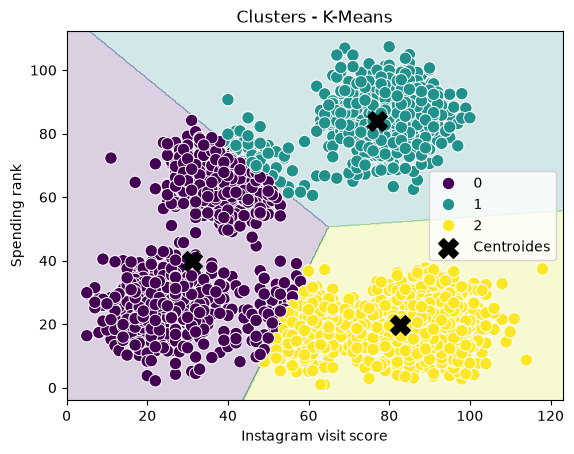

In [41]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dados utilizados no treinamento
X = data[['Instagram visit score', 'Spending_rank(0 to 100)']]

# Cria uma grade de pontos cobrindo o gráfico
x_min = X.iloc[:, 0].min() - 5
x_max = X.iloc[:, 0].max() + 5
y_min = X.iloc[:, 1].min() - 5
y_max = X.iloc[:, 1].max() + 5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

# Classifica cada ponto da grade
Z = kmeans.predict(
    np.c_[xx.ravel(), yy.ravel()]
)

Z = Z.reshape(xx.shape)

# Região dos clusters
plt.contourf(xx, yy, Z, alpha=0.2)

# Pontos
sns.scatterplot(
    data=data,
    x='Instagram visit score',
    y='Spending_rank(0 to 100)',
    hue='cluster',
    palette='viridis',
    s=80
)

# Centros dos clusters
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker='X',
    s=200,
    color='black',
    label='Centroides'
)

plt.title('Clusters - K-Means')
plt.xlabel('Instagram visit score')
plt.ylabel('Spending rank')
plt.legend()
plt.show()